## **CN2 Rule Induction**

**CN2** learns an **ordered list of IF ⟶ THEN rules** directly from labelled data: a beam search proposes conjunctions of `attribute = value`, a likelihood-ratio test discards the ones that could be chance, and the covered examples are removed before the next rule is learned.
This notebook keeps the original CN2 implementation and adds **rule-level test quality, the effect of the rule order, a cross-validation that refits the discretiser inside every fold, calibration and reference models**.

**Notebooks of this series:** 1. CN2 Rule Induction · 2. Expert Systems · 3. Case-Based Reasoning · 4. Apriori for Classification ( CBA ) · 5. Simple Rule Learners ( ZeroR, OneR, PRISM ) · 6. RIPPER · 7. Rules from Decision Trees · 8. RuleFit · 9. Fuzzy Rule-Based Classifier

### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

In [3]:
#Helper Functions: Evaluation Reports ( Confusion Matrix, Metrics, ROC and Precision-Recall )
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss, matthews_corrcoef,
                             confusion_matrix, roc_curve, precision_recall_curve)

def plot_confusion(cm, labels, ax, title="Confusion matrix"):
    ax.imshow(cm, cmap="Reds"); ax.grid(False)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45 if len(labels) > 4 else 0, ha="right" if len(labels) > 4 else "center")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10 if len(labels) > 4 else 13,
                    color="white" if cm[i, j] > cm.max() / 2 else DARK)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)

def report_binary(y_true, y_pred, y_score, name="model", labels=("negative", "positive"), plot=True):
    """Confusion matrix, ROC and Precision-Recall curves + a Series with the main metrics (positive class = 1)."""
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "precision": precision_score(y_true, y_pred, zero_division=0), "recall": recall_score(y_true, y_pred),
               "F1": f1_score(y_true, y_pred), "MCC": matthews_corrcoef(y_true, y_pred),
               "ROC AUC": roc_auc_score(y_true, y_score), "PR AUC": average_precision_score(y_true, y_score)}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        plot_confusion(confusion_matrix(y_true, y_pred), list(labels), axes[0], f"Confusion matrix – {name}")
        fpr, tpr, _ = roc_curve(y_true, y_score)
        axes[1].plot(fpr, tpr, color=RED, lw=2.4, label=f"AUC = {metrics['ROC AUC']:.3f}"); axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--")
        axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
        p, r, _ = precision_recall_curve(y_true, y_score)
        axes[2].plot(r, p, color=DARK, lw=2.4, label=f"AP = {metrics['PR AUC']:.3f}"); axes[2].axhline(y_true.mean(), color=GRAY, ls="--")
        axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_title("Precision–Recall curve"); axes[2].legend(loc="lower left")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)

def report_multiclass(y_true, y_pred, y_proba, labels, name="model", plot=True):
    """Confusion matrix, one-vs-rest ROC curves and per-class F1 + a Series with the main metrics."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    k = len(labels)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
               "macro recall": recall_score(y_true, y_pred, average="macro"), "macro F1": f1_score(y_true, y_pred, average="macro"),
               "MCC": matthews_corrcoef(y_true, y_pred), "ROC AUC (ovr)": roc_auc_score(y_true, y_proba, multi_class="ovr"),
               "log loss": log_loss(y_true, y_proba, labels=list(range(k)))}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
        plot_confusion(confusion_matrix(y_true, y_pred, labels=list(range(k))), list(labels), axes[0], f"Confusion matrix – {name}")
        cmap = plt.get_cmap("tab10")
        for c in range(k):
            fpr, tpr, _ = roc_curve((y_true == c).astype(int), y_proba[:, c])
            axes[1].plot(fpr, tpr, color=cmap(c), lw=1.6, label=f"{labels[c]}")
        axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
        axes[1].set_title(f"ROC one-vs-rest (macro AUC = {metrics['ROC AUC (ovr)']:.3f})"); axes[1].legend(fontsize=7, ncol=2 if k > 5 else 1, loc="lower right")
        f1s = f1_score(y_true, y_pred, average=None)
        axes[2].bar(range(k), f1s, color=RED, width=0.65); axes[2].set_xticks(range(k)); axes[2].set_xticklabels(labels, rotation=45 if k > 4 else 0, ha="right" if k > 4 else "center")
        axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("F1"); axes[2].set_title("F1 per class")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)
def annotate_heatmap(ax, mat, fmt="{:.2f}"):
    """Write the values on an imshow heat map with a readable text color."""
    mat = np.asarray(mat, dtype=float)
    lo, hi = np.nanmin(mat), np.nanmax(mat)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat[i, j]
            ax.text(j, i, "–" if np.isnan(v) else fmt.format(v), ha="center", va="center", color="white" if (not np.isnan(v) and v > (lo + hi) / 2) else DARK)

### **1. Rule-Based Techniques**

Models whose knowledge is a set of **IF ⟶ THEN** rules: transparent, auditable and easy to explain.

| Technique | Where the rules come from | Idea |
|---|---|---|
| **CN2** | learned from data | ordered rule list built by beam search (entropy + significance test) |
| **Expert system** | written by specialists | inference engine + knowledge base, with certainty factors |
| **Case-Based Reasoning** | no explicit rules: past **cases** | retrieve · reuse · revise · retain |
| **Apriori (CBA)** | mined from data | class association rules: frequent itemsets → class |

This notebook focuses on **CN2**. All the techniques of the series are applied to the same problem: **malignant × benign** tumours ( Breast Cancer dataset ).

### **2. Dataset and Preparation**

* Positive class = **malignant** (1) · 10 *mean* attributes (readable rules)
* Train/test split **70/30**, stratified
* For CN2 and Apriori the attributes are **discretised** in 3 quantile bins (*low / mid / high*), fitted on the **training set only**

In [4]:
#Load the Breast Cancer Dataset ( Positive Class = Malignant )
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer(as_frame=True)
cols = [c for c in data.data.columns if c.startswith("mean ")]            # 10 "mean" attributes
X = data.data[cols]
y = (data.target == 0).astype(int)                                        # 1 = malignant, 0 = benign
CLASS_NAMES = ["benign", "malignant"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
print("train:", X_train.shape, "| test:", X_test.shape, "| malignant in train:", f"{y_train.mean():.1%}")
X_train.head(3)

train: (398, 10) | test: (171, 10) | malignant in train: 37.2%


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension
78,20.18,23.97,143.70,1245.0,0.129,0.345,0.375,0.160,0.291,0.081
330,16.03,15.51,105.80,793.2,0.095,0.137,0.120,0.070,0.178,0.060
378,13.66,15.15,88.27,580.6,0.083,0.075,0.042,0.025,0.179,0.059


In [5]:
#Discretise the Attributes ( Quantile Bins Fitted on the Training Set )
from sklearn.preprocessing import KBinsDiscretizer

disc = KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="quantile", quantile_method="averaged_inverted_cdf").fit(X_train)
LEVELS = np.array(["low", "mid", "high"])

def to_categorical(Xnum):
    codes = disc.transform(Xnum).astype(int)
    return pd.DataFrame(LEVELS[codes], columns=[c.replace("mean ", "") for c in Xnum.columns], index=Xnum.index)

Xc_train, Xc_test = to_categorical(X_train), to_categorical(X_test)
Xc_train.head(3)

,radius,texture,perimeter,area,smoothness,compactness,concavity,concave points,symmetry,fractal dimension
78,high,high,high,high,high,high,high,high,high,high
330,high,low,high,high,mid,high,high,high,mid,mid
378,mid,low,mid,mid,low,mid,mid,mid,mid,mid


### **3. CN2 Rule Induction**

CN2 (Clark & Niblett, 1989) learns an **ordered rule list**:

1. **Beam search** for the best *complex* (conjunction of `attribute = value`) using **entropy** of the covered examples
2. Keep it only if it is **statistically significant** (likelihood-ratio statistic, $\chi^2$ test)
3. Add the rule (majority class of the covered examples), **remove** the covered examples and repeat
4. Finish with a **default rule**

$$\text{LRS} = 2 \sum_i f_i \ln \frac{f_i}{e_i} \qquad \text{entropy} = -\sum_i p_i \log_2 p_i$$

In [6]:
#CN2 Implementation ( Ordered Rule List with Beam Search, Entropy and Likelihood-Ratio Significance )
from scipy.stats import chi2

class CN2:
    def __init__(self, beam_width=5, max_len=4, alpha=0.05, min_cover=5):
        self.beam_width, self.max_len, self.alpha, self.min_cover = beam_width, max_len, alpha, min_cover

    @staticmethod
    def _entropy(counts):
        p = counts[counts > 0] / counts.sum()
        return -(p * np.log2(p)).sum()

    @staticmethod
    def _lrs(counts, prior):
        expected, m = prior * counts.sum(), counts > 0
        return 2 * (counts[m] * np.log(counts[m] / expected[m])).sum()

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        yi, k = np.searchsorted(self.classes_, y), len(self.classes_)
        selectors = [(c, v) for c in X.columns for v in sorted(X[c].unique())]
        masks = {s: (X[s[0]] == s[1]).to_numpy() for s in selectors}
        crit = chi2.ppf(1 - self.alpha, k - 1)
        remaining, self.rules_ = np.ones(len(X), bool), []
        while remaining.sum() > 0:
            prior = np.bincount(yi[remaining], minlength=k) / remaining.sum()
            best, best_ent, star = None, np.inf, [()]
            for depth in range(1, self.max_len + 1):
                cands = {}
                for cx in star:
                    used = {a for a, _ in cx}
                    for s in selectors:
                        if s[0] in used:
                            continue
                        new = tuple(sorted(cx + (s,)))
                        if new in cands:
                            continue
                        m = remaining.copy()
                        for sel in new:
                            m &= masks[sel]
                        if m.sum() < self.min_cover:
                            continue
                        counts = np.bincount(yi[m], minlength=k)
                        cands[new] = (self._entropy(counts), counts)
                if not cands:
                    break
                ranked = sorted(cands.items(), key=lambda kv: (kv[1][0], -kv[1][1].sum()))
                for cx, (ent, counts) in ranked:
                    if ent < best_ent and self._lrs(counts, prior) > crit:
                        best, best_ent = cx, ent
                star = [cx for cx, _ in ranked[:self.beam_width]]
            if best is None:
                break
            m = remaining.copy()
            for sel in best:
                m &= masks[sel]
            counts = np.bincount(yi[m], minlength=k)
            self.rules_.append({"conds": best, "cls": int(counts.argmax()), "counts": counts, "lrs": self._lrs(counts, prior)})
            remaining &= ~m
        default_counts = np.bincount(yi[remaining], minlength=k) if remaining.sum() else np.bincount(yi, minlength=k)
        self.default_ = {"conds": (), "cls": int(default_counts.argmax()), "counts": default_counts, "lrs": np.nan}
        return self

    def _rule_mask(self, X, rule):
        m = np.ones(len(X), bool)
        for a, v in rule["conds"]:
            m &= (X[a] == v).to_numpy()
        return m

    def predict_proba(self, X):
        k = len(self.classes_)
        proba, free = np.zeros((len(X), k)), np.ones(len(X), bool)
        for rule in self.rules_ + [self.default_]:
            m = self._rule_mask(X, rule) & free
            proba[m] = (rule["counts"] + 1) / (rule["counts"].sum() + k)           # Laplace estimate
            free &= ~m
        return proba

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

    def rules_table(self):
        rows = []
        for i, r in enumerate(self.rules_ + [self.default_], 1):
            text = " AND ".join(f"{a}={v}" for a, v in r["conds"]) or "(default)"
            rows.append({"#": i, "IF": text, "THEN": CLASS_NAMES[self.classes_[r["cls"]]], "covers": int(r["counts"].sum()),
                         "precision": r["counts"][r["cls"]] / r["counts"].sum(), "LRS": r["lrs"], "length": len(r["conds"])})
        return pd.DataFrame(rows).set_index("#")

In [7]:
#Fit CN2 and Show the Learned Rule List
cn2 = CN2(beam_width=5, max_len=4, alpha=0.05, min_cover=5).fit(Xc_train, y_train)
rules_df = cn2.rules_table()
print(f"{len(cn2.rules_)} rules + default rule")
rules_df

21 rules + default rule


,IF,THEN,covers,precision,LRS,length
#,,,,,,
1,concave points=low AND perimeter=low,benign,85,1.000,79.048,2
2,concave points=high AND texture=high,malignant,66,1.000,98.867,2
3,concavity=low AND texture=low,benign,32,1.000,25.820,2
4,area=low AND concavity=mid,benign,32,1.000,30.738,2
5,concave points=low AND symmetry=low,benign,17,1.000,20.208,2
6,area=high AND fractal dimension=high,malignant,11,1.000,15.516,2
7,area=high AND concavity=high AND texture=mid,malignant,23,1.000,35.914,3
8,symmetry=low AND texture=low,benign,9,1.000,8.136,2
9,area=mid AND concave points=mid AND smoothness...,benign,15,1.000,14.841,3


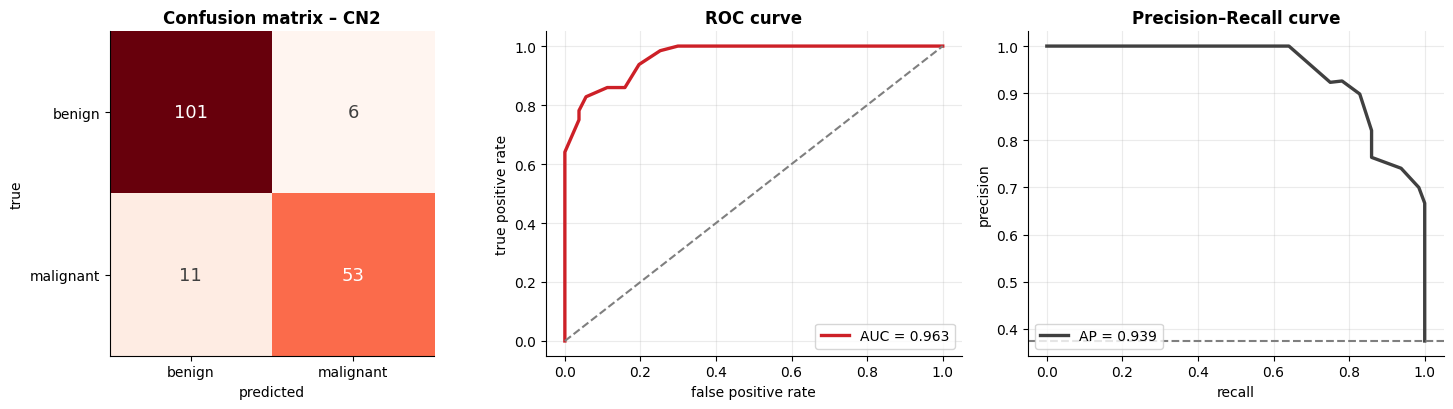

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
CN2,0.901,0.886,0.898,0.828,0.862,0.786,0.963,0.939


In [8]:
#Evaluate CN2 on the Test Set ( Confusion Matrix, ROC and Precision-Recall )
proba_cn2 = cn2.predict_proba(Xc_test)[:, 1]
pred_cn2 = cn2.predict(Xc_test)
results = {}
results["CN2"] = report_binary(y_test, pred_cn2, proba_cn2, "CN2", CLASS_NAMES)
results["CN2"].to_frame().T

#### **CN2-Specific Metrics**

Rule **coverage** and **precision**, the **significance** (LRS) and the **rule length**. Rules are ordered: each one only sees what the previous ones left uncovered.

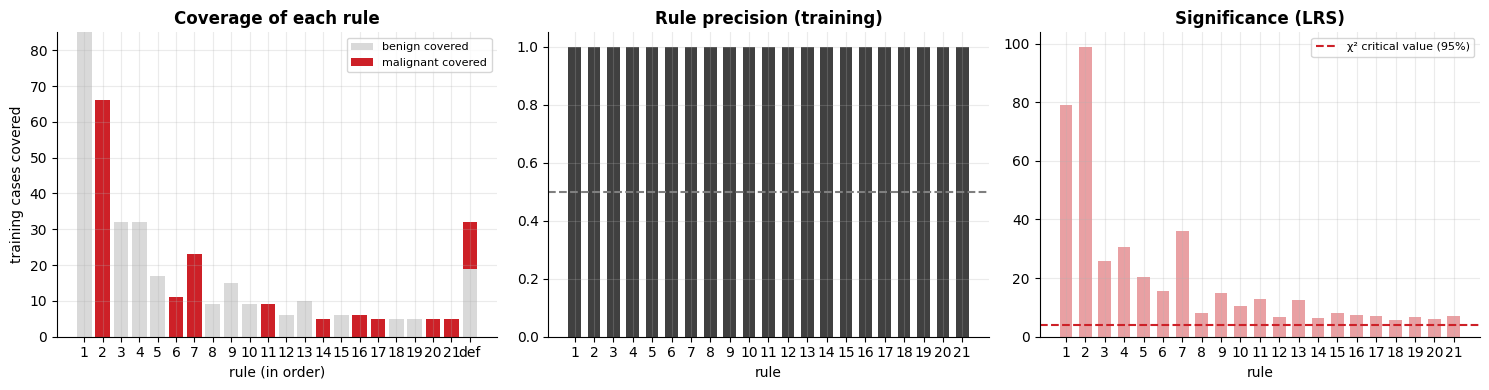

rules: 21 | mean length: 2.57 | rules covering ≥ 90% of one class: 21


In [9]:
#Rule Quality: Coverage by Class, Precision and Significance
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rr = cn2.rules_ + [cn2.default_]
idx = np.arange(len(rr))
benign_c = [r["counts"][0] for r in rr]; malig_c = [r["counts"][1] for r in rr]
axes[0].bar(idx, benign_c, color=LIGHT, label="benign covered"); axes[0].bar(idx, malig_c, bottom=benign_c, color=RED, label="malignant covered")
axes[0].set_xticks(idx); axes[0].set_xticklabels([str(i + 1) if i < len(cn2.rules_) else "def" for i in idx]); axes[0].set_xlabel("rule (in order)"); axes[0].set_ylabel("training cases covered")
axes[0].set_title("Coverage of each rule"); axes[0].legend(fontsize=8)
axes[1].bar(idx[:-1], rules_df["precision"].iloc[:-1], color=DARK, width=0.65); axes[1].set_ylim(0, 1.05); axes[1].axhline(0.5, color=GRAY, ls="--")
axes[1].set_xticks(idx[:-1]); axes[1].set_xticklabels([str(i + 1) for i in idx[:-1]]); axes[1].set_xlabel("rule"); axes[1].set_title("Rule precision (training)")
axes[2].bar(idx[:-1], rules_df["LRS"].iloc[:-1], color=SOFT, width=0.65); axes[2].axhline(chi2.ppf(0.95, 1), color=RED, ls="--", label="χ² critical value (95%)")
axes[2].set_xticks(idx[:-1]); axes[2].set_xticklabels([str(i + 1) for i in idx[:-1]]); axes[2].set_xlabel("rule"); axes[2].set_title("Significance (LRS)"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"rules: {len(cn2.rules_)} | mean length: {rules_df['length'].iloc[:-1].mean():.2f} | rules covering ≥ 90% of one class: {(rules_df['precision'].iloc[:-1] >= 0.9).sum()}")

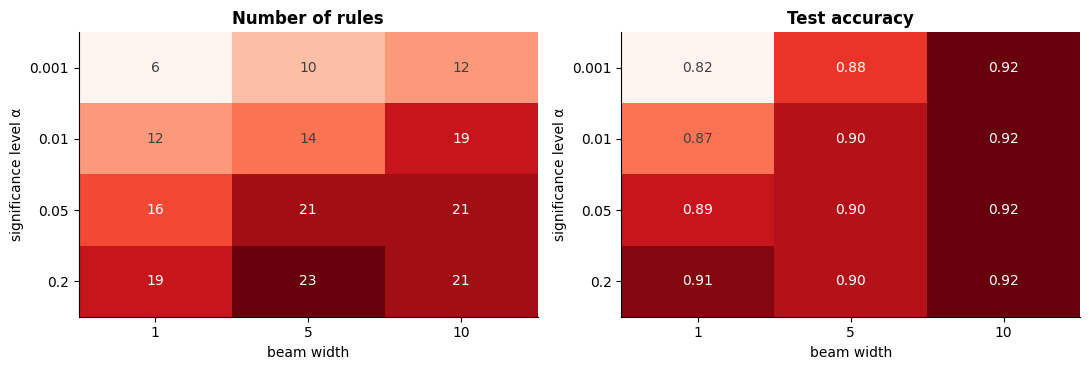

In [10]:
#Sensitivity of CN2: Significance Level and Beam Width
rows = []
for alpha in [0.2, 0.05, 0.01, 0.001]:
    for beam in [1, 5, 10]:
        m = CN2(beam_width=beam, alpha=alpha).fit(Xc_train, y_train)
        rows.append({"alpha": alpha, "beam": beam, "rules": len(m.rules_), "test accuracy": accuracy_score(y_test, m.predict(Xc_test))})
sens = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in zip(axes, ["rules", "test accuracy"], ["Number of rules", "Test accuracy"]):
    piv = sens.pivot(index="alpha", columns="beam", values=col)
    ax.imshow(piv, cmap="Reds", aspect="auto"); ax.grid(False)
    ax.set_xticks(range(3)); ax.set_xticklabels(piv.columns); ax.set_yticks(range(4)); ax.set_yticklabels(piv.index)
    ax.set_xlabel("beam width"); ax.set_ylabel("significance level α"); ax.set_title(title)
    annotate_heatmap(ax, piv.to_numpy(), "{:.0f}" if col == "rules" else "{:.2f}")
plt.tight_layout(); plt.show()

A **stricter** α gives **fewer rules** (a simpler list) but, with a narrow beam, loses accuracy (beam 1: ≈ 0.82 at α = 0.001 vs ≈ 0.91 at α = 0.2). A **wider beam** recovers it at a higher search cost.

### **4. Quality Metrics Beyond the Original Ones**

In [ ]:
#Which Rule Decides Each Test Case? Test Precision of Each Rule vs Its Training Precision
free = np.ones(len(Xc_test), bool)
rows = []
for i, rule in enumerate(cn2.rules_ + [cn2.default_], 1):
    m = cn2._rule_mask(Xc_test, rule) & free
    free &= ~m
    rows.append({"rule": i if i <= len(cn2.rules_) else "default", "test cases decided": int(m.sum()),
                 "test precision": (y_test.to_numpy()[m] == rule["cls"]).mean() if m.any() else np.nan,
                 "training precision": rule["counts"][rule["cls"]] / rule["counts"].sum()})
decided = pd.DataFrame(rows)
used = decided.dropna(subset=["test precision"])
gap = ((used["training precision"] - used["test precision"]) * used["test cases decided"]).sum() / used["test cases decided"].sum()
print(f"rules that decide at least one test case: {len(used) - int(used['rule'].eq('default').any())} of {len(cn2.rules_)} | weighted gap between training and test precision: {gap:+.3f}")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(np.arange(len(used)) - 0.2, used["training precision"], width=0.4, color=LIGHT, label="training precision")
ax.bar(np.arange(len(used)) + 0.2, used["test precision"], width=0.4, color=RED, label="test precision")
ax.set_xticks(range(len(used))); ax.set_xticklabels(used["rule"].astype(str)); ax.set_xlabel("rule ( only rules that decided at least one test case )"); ax.set_ylim(0, 1.05); ax.legend(fontsize=8, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
plt.tight_layout(); plt.show()
decided.round(3).head(8)

In [ ]:
#Does the Order of the Rules Matter? Same Rules, Shuffled 30 Times
import copy
rng_o = np.random.default_rng(RANDOM_STATE)
shuffled_acc = []
for _ in range(30):
    shuffled = copy.copy(cn2)
    shuffled.rules_ = [cn2.rules_[i] for i in rng_o.permutation(len(cn2.rules_))]
    shuffled_acc.append(accuracy_score(y_test, shuffled.predict(Xc_test)))
print(f"learned order: accuracy {accuracy_score(y_test, cn2.predict(Xc_test)):.3f} | shuffled order: mean {np.mean(shuffled_acc):.3f}, min {np.min(shuffled_acc):.3f}, max {np.max(shuffled_acc):.3f}")
print("the rules were learned one after another on the cases left by the previous ones, so the order is part of the model; here the rules are very precise and mostly disjoint, so a shuffle changes few predictions")

In [ ]:
#Repeated Stratified CV on the Training Set ( 5 Folds x 3 ): the Discretiser and CN2 Are Refitted Inside Every Fold
from sklearn.model_selection import RepeatedStratifiedKFold
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

def cv_cn2(**params):
    accs, aucs, sizes = [], [], []
    for tr, te in cv_rep.split(X_train, y_train):
        d = KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="quantile", quantile_method="averaged_inverted_cdf").fit(X_train.iloc[tr])
        codes = lambda part: pd.DataFrame(LEVELS[d.transform(part).astype(int)], columns=Xc_train.columns, index=part.index)
        model = CN2(**params).fit(codes(X_train.iloc[tr]), y_train.iloc[tr])
        p = model.predict_proba(codes(X_train.iloc[te]))[:, 1]
        accs.append(((p > 0.5).astype(int) == y_train.iloc[te].to_numpy()).mean()); aucs.append(roc_auc_score(y_train.iloc[te], p)); sizes.append(len(model.rules_))
    return np.array(accs), np.array(aucs), np.array(sizes)

accs, aucs, sizes = cv_cn2(beam_width=5, max_len=4, alpha=0.05, min_cover=5)
cn2_cv = {"accuracy ( mean )": accs.mean(), "accuracy ( std )": accs.std(), "ROC AUC ( mean )": aucs.mean(), "ROC AUC ( std )": aucs.std()}
print(f"CN2 in 15 folds: rules per model {sizes.mean():.1f} ± {sizes.std():.1f} ( min {sizes.min()}, max {sizes.max()} ) -> the learned list changes from fold to fold")

In [ ]:
#Reference Models on the Same Split ( Is the Technique Better than a Trivial or a Standard Model? )
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

references = {"Majority class": DummyClassifier(strategy="prior"),
              "Decision tree ( depth 3 )": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
              "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))}
reference_rows = {}
for ref_name, model in references.items():
    model.fit(X_train, y_train)
    reference_rows[ref_name] = report_binary(y_test, model.predict(X_test), model.predict_proba(X_test)[:, 1], ref_name, CLASS_NAMES, plot=False)
metric_cols = ["accuracy", "precision", "recall", "F1", "ROC AUC", "PR AUC"]
pd.concat([pd.DataFrame(results).T[metric_cols], pd.DataFrame(reference_rows).T[metric_cols]]).round(3)

In [ ]:
#Same Repeated CV for the Reference Models ( Numeric Attributes, Refitted in Every Fold )
from sklearn.model_selection import cross_validate
cv_rows = {}
for ref_name, model in references.items():
    res = cross_validate(model, X_train, y_train, cv=cv_rep, scoring=["accuracy", "roc_auc"])
    cv_rows[ref_name] = {"accuracy ( mean )": res["test_accuracy"].mean(), "accuracy ( std )": res["test_accuracy"].std(), "ROC AUC ( mean )": res["test_roc_auc"].mean(), "ROC AUC ( std )": res["test_roc_auc"].std()}
cv_table = pd.concat([pd.DataFrame(cv_rows).T, pd.DataFrame({"CN2 ( discretised )": cn2_cv}).T]).round(3)
cv_table

In [ ]:
#Calibration of the Predicted Probabilities ( Brier Score and Reliability Curve )
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

proba_cn2_ARRAY = np.asarray(proba_cn2, dtype=float)
frac_pos, mean_pred = calibration_curve(y_test, proba_cn2_ARRAY, n_bins=5, strategy="quantile")                       # bins with the same number of cases
print(f"Brier score: {brier_score_loss(y_test, proba_cn2_ARRAY):.4f} | Brier score of a model that always predicts the training prevalence: {brier_score_loss(y_test, np.full(len(y_test), y_train.mean())):.4f} ( lower is better )")
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", label="perfect calibration"); ax.plot(mean_pred, frac_pos, color=RED, marker="o", label="CN2")
ax.set_xlabel("mean predicted probability ( 5 bins of equal size )"); ax.set_ylabel("observed share of malignant"); ax.set_title("Reliability curve"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
#Uncertainty of the Test Metrics ( Bootstrap of the Test Cases, 1,000 Resamples )
def bootstrap_ci(y_true, pred, score, n_boot=1000, seed=RANDOM_STATE):
    rng_b = np.random.default_rng(seed)
    y_true, pred, score = np.asarray(y_true), np.asarray(pred), np.asarray(score)
    acc, auc = [], []
    for _ in range(n_boot):
        i = rng_b.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[i])) < 2:
            continue
        acc.append((pred[i] == y_true[i]).mean())
        auc.append(roc_auc_score(y_true[i], score[i]))
    return pd.DataFrame({"accuracy": np.percentile(acc, [2.5, 50, 97.5]), "ROC AUC": np.percentile(auc, [2.5, 50, 97.5])}, index=["2.5%", "median", "97.5%"]).T

print("the test set has", len(y_test), "cases: differences smaller than these intervals are not reliable")
bootstrap_ci(y_test, pred_cn2, proba_cn2).round(3)

### **5. Takeaways**

* CN2 produces a **short, readable list**, but the list is **not stable**: the number of rules changes from fold to fold ( section 4 ), so read the rules as *one* explanation, not *the* explanation
* The **order is part of the model** ( each rule was learned on the cases left by the previous ones ), although in this dataset the rules are so precise and so disjoint that shuffling them changes the accuracy only slightly and not always for the worse ( section 4 )
* The rules were chosen on the training set: compare the **test precision** of each rule with its training precision before trusting it
* With 171 test cases the intervals of the bootstrap are wide: do not rank techniques by differences smaller than them
* A **reference model** ( logistic regression, shallow tree ) puts the numbers in perspective: the value of CN2 is the **interpretability**, not the accuracy